Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Berhasil import utils_cv! Langsung mulai proses...

--- L2.3: Kontras Bercak (KB) per kanal (teh_041) ---
KB kanal B   : 1.49
KB kanal G   : 1.88
KB kanal R   : 7.05
KB kanal Gray: 4.53
KB kanal H   : 3.93
KB kanal S   : 0.14
KB kanal V   : 3.08

--- L2.4: Sampling ---
fx=0.5: ukuran (240, 320), KB=5.88
fx=0.2: ukuran (96, 128), KB=5.25
fx=0.1: ukuran (48, 64), KB=3.41
fx=0.05: ukuran (24, 32), KB=1.61

--- L2.4: Kuantisasi ---
k=1: 2 level, KB=4.41
k=2: 3 level, KB=4.53
k=3: 6 level, KB=2.83
k=4: 11 level, KB=4.14
k=8: 163 level, KB=4.53

--- L2.5: Rerata KB Kelas Berat ---
                   B     G      R  Gray     H     S     V
kondisi                                                  
bayangan        1.24  0.62   5.95  1.85  5.35  0.85  1.09
gelap           1.43  1.67  10.58  4.91  5.83  0.72  3.71
kontras_rendah  0.81  0.70   3.78  2.39  1.56  0.13  1.

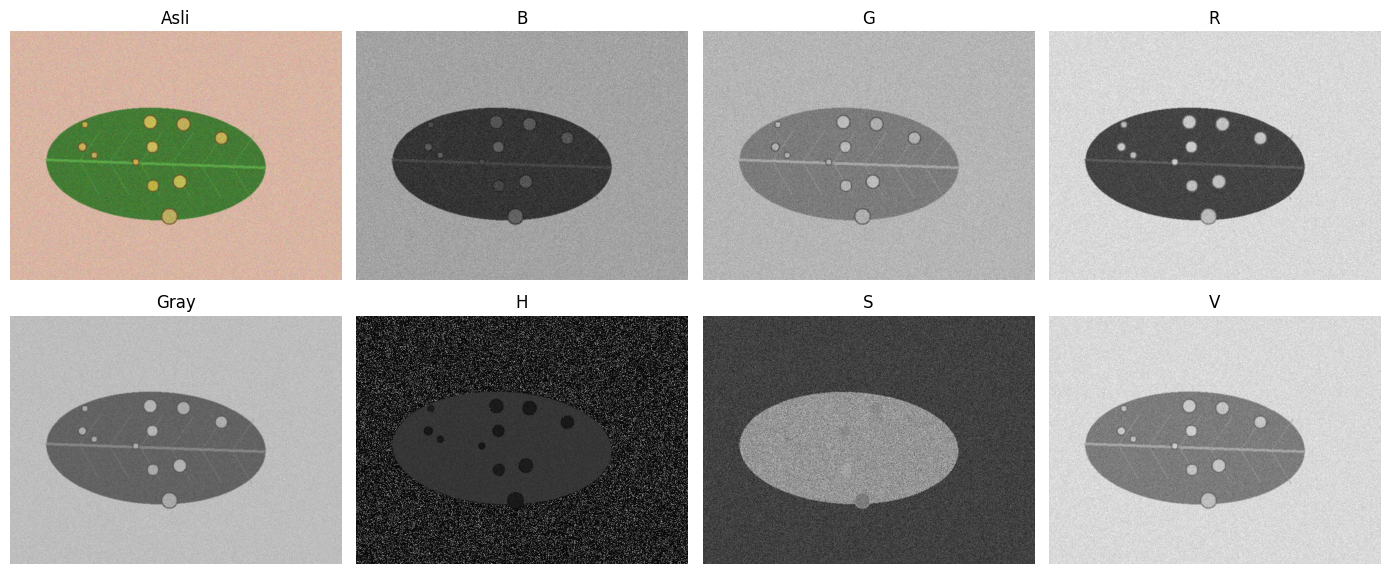

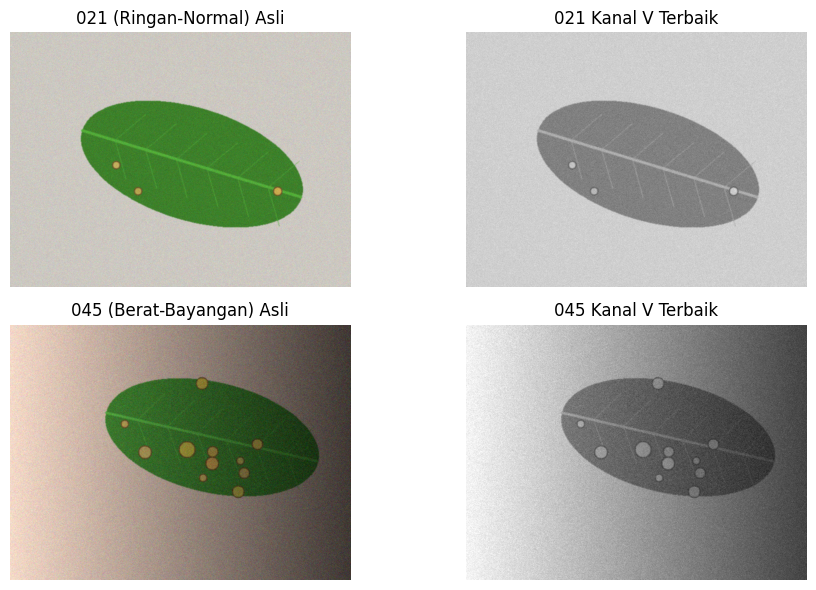

In [10]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys
sys.path.append('/content/drive/MyDrive/simuteh-2330511031/src')

# Pastikan folder ada
base_dir = '/content/drive/MyDrive/simuteh-2330511031'
os.makedirs(f'{base_dir}/src', exist_ok=True)
os.makedirs(f'{base_dir}/notebook', exist_ok=True)

# Tulis paksa utils_cv.py biar nggak hilang lagi
with open(f'{base_dir}/src/utils_cv.py', 'w') as f:
    f.write('''import cv2
import numpy as np
import matplotlib.pyplot as plt

def baca(path):
    img = cv2.imread(path)
    if img is None: raise FileNotFoundError(f"Citra tidak ditemukan: {path}")
    return img

def tampil(daftar, judul, baris=1, ukuran=(14, 4)):
    kolom = int(np.ceil(len(daftar) / baris))
    plt.figure(figsize=ukuran)
    for i, (im, jd) in enumerate(zip(daftar, judul)):
        plt.subplot(baris, kolom, i + 1)
        if im.ndim == 3: plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else: plt.imshow(im, cmap="gray", vmin=0, vmax=255)
        plt.title(jd)
        plt.axis("off")
    plt.tight_layout()

def kontras_bercak(kanal, mask_daun, mask_bercak):
    k = kanal.astype(np.float64)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    bercak = mask_bercak > 0
    if bercak.sum() == 0: return float("nan")
    return abs(k[bercak].mean() - k[sehat].mean()) / (k[sehat].std() + 1e-6)

def statistik(gray):
    return {"rerata": round(float(gray.mean()), 1),
            "simpangan_baku": round(float(gray.std()), 1),
            "min": int(gray.min()), "maks": int(gray.max()),
            "persen_gelap": round(100 * float((gray < 50).mean()), 1),
            "persen_terang": round(100 * float((gray > 205).mean()), 1)}
''')

# Pindah ke notebook & masukin folder src ke sistem
os.chdir(f'{base_dir}/notebook')
if '../src' not in sys.path:
    sys.path.append('../src')

# --- 2. JALANKAN TUGAS BAGIAN 2 (Langkah 2.3 - 2.6) ---
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak

print("✅ Berhasil import utils_cv! Langsung mulai proses...\n")

# L2.3 & L2.4: Kanal Warna, Sampling, Kuantisasi
nama_41 = "teh_041.png"
img_41 = baca(f"../data/sintetis/citra/{nama_41}")
md_41 = cv2.imread(f"../data/sintetis/mask_daun/{nama_41}", 0)
mb_41 = cv2.imread(f"../data/sintetis/mask_bercak/{nama_41}", 0)
gray_41 = cv2.cvtColor(img_41, cv2.COLOR_BGR2GRAY)
hsv_41 = cv2.cvtColor(img_41, cv2.COLOR_BGR2HSV)
b, g, r = cv2.split(img_41)
h, s, v = cv2.split(hsv_41)

kanal = {"B": b, "G": g, "R": r, "Gray": gray_41, "H": h, "S": s, "V": v}
print("--- L2.3: Kontras Bercak (KB) per kanal (teh_041) ---")
for nm, c in kanal.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md_41, mb_41):.2f}")
tampil([img_41] + list(kanal.values()), ["Asli"] + list(kanal.keys()), baris=2, ukuran=(14, 6))

print("\n--- L2.4: Sampling ---")
for fx in [0.5, 0.2, 0.1, 0.05]:
    kecil = cv2.resize(gray_41, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
    besar = cv2.resize(kecil, gray_41.shape[::-1], interpolation=cv2.INTER_NEAREST)
    print(f"fx={fx}: ukuran {kecil.shape}, KB={kontras_bercak(besar, md_41, mb_41):.2f}")

print("\n--- L2.4: Kuantisasi ---")
for k in [1, 2, 3, 4, 8]:
    langkah = 256 // (2 ** k)
    kuant = (gray_41 // langkah) * langkah
    print(f"k={k}: {len(np.unique(kuant))} level, KB={kontras_bercak(kuant, md_41, mb_41):.2f}")

# L2.5: Uji KB 20 Citra Kelas Berat
def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(img)
    h, s, v = cv2.split(hsv)
    return {"B": b, "G": g, "R": r, "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), "H": h, "S": s, "V": v}

label = pd.read_csv("../data/sintetis/label.csv")
baris_berat = []
for _, d in label[label.kelas == "berat"].iterrows():
    im = baca(f"../data/sintetis/citra/{d.nama_file}")
    m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
    kb["kondisi"] = d.kondisi_cahaya
    baris_berat.append(kb)

print("\n--- L2.5: Rerata KB Kelas Berat ---")
tabel_kb_berat = pd.DataFrame(baris_berat).groupby("kondisi").mean().round(2)
print(tabel_kb_berat)
tabel_kb_berat.to_csv("../hasil/b2_kb_kanal_berat.csv")

# L2.6: Uji KB 20 Citra Kelas Ringan & Kanal Terbaik
baris_ringan = []
for _, d in label[label.kelas == "ringan"].iterrows():
    im = baca(f"../data/sintetis/citra/{d.nama_file}")
    m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
    kb["kondisi"] = d.kondisi_cahaya
    baris_ringan.append(kb)

print("\n--- L2.6: Rerata KB Kelas Ringan ---")
tabel_kb_ringan = pd.DataFrame(baris_ringan).groupby("kondisi").mean().round(2)
print(tabel_kb_ringan)

# Menampilkan Kanal Terbaik (V) untuk teh_021 dan teh_045
img_21 = baca("../data/sintetis/citra/teh_021.png")
v_21 = cv2.split(cv2.cvtColor(img_21, cv2.COLOR_BGR2HSV))[2]
img_45 = baca("../data/sintetis/citra/teh_045.png")
v_45 = cv2.split(cv2.cvtColor(img_45, cv2.COLOR_BGR2HSV))[2]

tampil([img_21, v_21, img_45, v_45],
       ["021 (Ringan-Normal) Asli", "021 Kanal V Terbaik",
        "045 (Berat-Bayangan) Asli", "045 Kanal V Terbaik"], baris=2, ukuran=(10, 6))